# Sales Data Analysis
Exploratory data analysis on sales dataset.


In [2]:
# Import required libraries: numpy, pandas, matplotlib, seaborn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Import From CSV 

In [3]:
# Load sales data from CSV file
df = pd.read_csv(r'D:\coding\Data analysis\Python\project\Sales_Data.csv', encoding='unicode_escape' )

In [4]:
# Check shape of dataset (rows, columns)
df.shape

(11257, 13)

In [5]:
# Statistical summary of numerical columns
df.describe()

,User_ID,Age,Zipcode,Orders,Amount
count,1.124500e+04,11245.000000,0.0,11245.000000,11245.000000
mean,1.003004e+06,35.415651,NaN,3.500311,9461.934237
std,1.716207e+03,12.756369,NaN,1.713706,5234.426634
min,1.000001e+06,12.000000,NaN,1.000000,188.000000
25%,1.001492e+06,27.000000,NaN,2.000000,5443.000000
50%,1.003065e+06,33.000000,NaN,4.000000,8109.000000
75%,1.004429e+06,43.000000,NaN,5.000000,12683.000000
max,1.006040e+06,92.000000,NaN,6.000000,29350.000000


In [6]:
# Dataset info: columns, dtypes, non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11257 entries, 0 to 11256
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11245 non-null  float64
 1   Cust_name         11245 non-null  str    
 2   Product_ID        11245 non-null  str    
 3   Age               11245 non-null  float64
 4   Age Group         11245 non-null  str    
 5   Gender            11245 non-null  str    
 6   State             11245 non-null  str    
 7   Zone              11245 non-null  str    
 8   Zipcode           0 non-null      float64
 9   Profession        11245 non-null  str    
 10  Product_Category  11245 non-null  str    
 11  Orders            11245 non-null  float64
 12  Amount            11245 non-null  float64
dtypes: float64(5), str(8)
memory usage: 1.1 MB


In [7]:
# Preview first 5 rows
df.head(5)

,User_ID,Cust_name,Product_ID,Age,Age Group,Gender,State,Zone,Zipcode,Profession,Product_Category,Orders,Amount
0,1002903.0,Anvi,P00125942,27.0,26-35,Female,Maharashtra,West,NaN,Healthcare,Sports,4.0,20500.0
1,1000732.0,Shanta,P00110942,34.0,26-35,Female,Andhra Pradesh,South,NaN,Govt,Sports,2.0,25360.0
2,1001990.0,Sheetal,P00118542,16.0,0-17,Female,Uttar Pradesh,Central,NaN,Automobile,Health,4.0,29350.0
3,1001425.0,Virendra,P00237842,16.0,0-17,M,Karnataka,South,NaN,Construction,Clothing,6.0,23500.0
4,1000588.0,Vishal,P00057942,28.0,26-35,M,Gujarat,West,NaN,Food Processing,Electronics,4.0,23870.0


## Data Cleaning

In [8]:
# Drop 'Zipcode' column (not needed)
# Drop zipcode column
df.drop(["Zipcode"], axis=1 ,inplace=True)

In [ ]:
# List all column names
df.columns.to_list()

In [9]:
# Count missing values per column
df.isnull().sum()

User_ID             12
Cust_name           12
Product_ID          12
Age                 12
Age Group           12
Gender              12
State               12
Zone                12
Profession          12
Product_Category    12
Orders              12
Amount              12
dtype: int64

In [10]:
# Drop rows that are completely null
df.dropna(how='all' , inplace=True)

In [11]:
# Re-check missing values after cleaning
df.isnull().sum()

User_ID             0
Cust_name           0
Product_ID          0
Age                 0
Age Group           0
Gender              0
State               0
Zone                0
Profession          0
Product_Category    0
Orders              0
Amount              0
dtype: int64

In [12]:
# Check shape after cleaning
df.shape

(11245, 12)

In [13]:
# Standardize Gender values: 'M' -> 'Male'
# Replace 
df['Gender'] = df['Gender'].replace('M','Male')

In [14]:
# Filter rows where Gender is Male
df[df['Gender']=='Male']

,User_ID,Cust_name,Product_ID,Age,Age Group,Gender,State,Zone,Profession,Product_Category,Orders,Amount
3,1001425.0,Virendra,P00237842,16.0,0-17,Male,Karnataka,South,Construction,Clothing,6.0,23500.0
4,1000588.0,Vishal,P00057942,28.0,26-35,Male,Gujarat,West,Food Processing,Electronics,4.0,23870.0
5,1000588.0,Suuraj,P00057942,28.0,26-35,Male,Himachal Pradesh,Northern,Food Processing,Electronics,3.0,23860.0
8,1003224.0,Kushal,P00205642,35.0,26-35,Male,Uttar Pradesh,Central,Govt,Beauty,4.0,23809.0
11,1003829.0,Harsh,P00200842,34.0,26-35,Male,Delhi,Central,Banking,Health,2.0,23770.0
...,...,...,...,...,...,...,...,...,...,...,...,...
11249,1005446.0,Sheetal,P00297742,53.0,51-55,Male,Gujarat,West,Healthcare,Health,3.0,382.0
11250,1005446.0,Sheetal,P00297742,53.0,51-55,Male,Madhya Pradesh,Central,Healthcare,Health,2.0,382.0
11252,1000695.0,Manning,P00296942,19.0,18-25,Male,Maharashtra,West,Chemical,Health,1.0,370.0
11253,1004089.0,Reichenbach,P00171342,33.0,26-35,Male,Haryana,Northern,Healthcare,Health,5.0,367.0


In [17]:
# Random sample of 10 rows
df.sample(10)

,User_ID,Cust_name,Product_ID,Age,Age Group,Gender,State,Zone,Profession,Product_Category,Orders,Amount
7810,1001867.0,McGarr,P0096442,54.0,51-55,Female,Telangana,South,Govt,Clothing,4.0,6150.0
1944,1000746.0,Uudhav,P00313342,25.0,18-25,Male,Kerala,South,Automobile,Sports,4.0,15614.0
455,1001281.0,Gjertsen,P00026042,31.0,26-35,Female,Gujarat,West,Automobile,Sports,2.0,19690.0
2753,1003476.0,Lalita,P00124842,55.0,51-55,Female,Uttar Pradesh,Central,Automobile,Beauty,2.0,12783.0
10672,1001675.0,Utsav,P00191742,29.0,26-35,Male,Maharashtra,West,Retail,Sports,1.0,2139.0
7073,1001279.0,Hitesh,P00014142,43.0,36-45,Female,Kerala,South,Chemical,Electronics,3.0,7075.0
11006,1000409.0,Melton,P00339542,20.0,18-25,Female,Karnataka,South,Aviation,Beauty,3.0,1542.0
6970,1003778.0,Dickinson,P00223042,29.0,26-35,Female,Karnataka,South,Media,Health,1.0,7111.0
7112,1001350.0,Raksha,P00230942,39.0,36-45,Male,Maharashtra,West,Lawyer,Sports,4.0,7057.0
9978,1000316.0,Zrebassa,P00206742,77.0,55+,Female,Uttarakhand,Central,Media,Health,1.0,3565.0


In [15]:
# Statistical summary after cleaning
df.describe()

,User_ID,Age,Orders,Amount
count,1.124500e+04,11245.000000,11245.000000,11245.000000
mean,1.003004e+06,35.415651,3.500311,9461.934237
std,1.716207e+03,12.756369,1.713706,5234.426634
min,1.000001e+06,12.000000,1.000000,188.000000
25%,1.001492e+06,27.000000,2.000000,5443.000000
50%,1.003065e+06,33.000000,4.000000,8109.000000
75%,1.004429e+06,43.000000,5.000000,12683.000000
max,1.006040e+06,92.000000,6.000000,29350.000000


In [16]:
# Total Amount spent by Gender
df.groupby('Gender', as_index=False)['Amount'].sum()

,Gender,Amount
0,Female,74461610.49
1,Male,31937840.00


## Data Visualization
### Gender Distribution


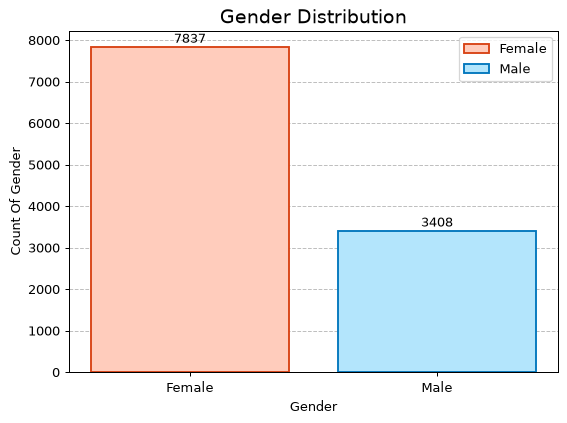

In [18]:
# Bar chart: count of transactions by Gender
# Total Transactions count by Gender Wise show in Bar Chart
gen_count = df['Gender'].value_counts()
fig,ax = plt.subplots(dpi=90)
ax.bar(
        gen_count.index,
        gen_count.values,
        zorder=2 ,
        edgecolor=['#D84315', '#0277BD'],
        color=["#FFCCBC", '#B3E5FC'],
        linewidth=1.5,
        label=["Female","Male"],
    )
bar = ax.bar(gen_count.index, gen_count.values)
ax.legend()
ax.grid(True ,alpha=.8 , linestyle='--', axis='y')
ax.set_ylabel("Count Of Gender")
ax.set_xlabel("Gender")
ax.set_title('Gender Distribution', fontsize=15)
ax.bar_label(bar, padding=1)
fig.tight_layout()
plt.show()

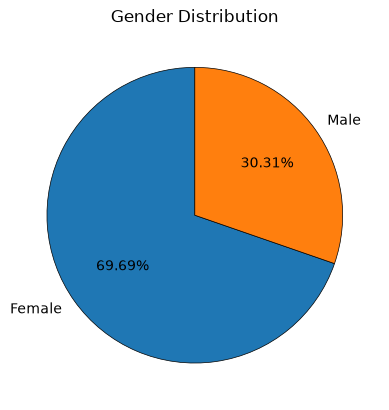

In [19]:
# Pie chart: Gender distribution percentage
plt.pie(
        gen_count,
        labels=gen_count.index,
        autopct='%.2f%%',
        startangle=90,
        wedgeprops={'edgecolor':'black','linewidth':.5}
    )
plt.title("Gender Distribution")
plt.show()

### Age Group Distribution


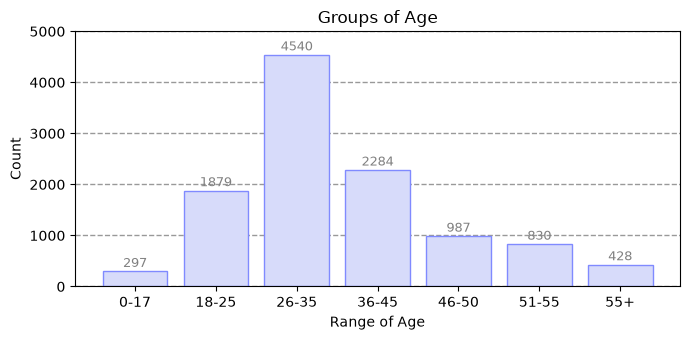

In [20]:
# Bar chart: count of customers by Age Group
x = df.groupby('Age Group')['Gender'].count()

fig, ax = plt.subplots(figsize=(7,3.5), dpi=100)
bar = ax.bar(x.index, x.values, width=.8, zorder=2, color='#D7DBFA', edgecolor='#808AFF')
ax.bar_label(bar, padding=1, color='gray', fontsize=9)
ax.set_title('Groups of Age')
ax.set_xlabel('Range of Age')
ax.set_ylabel('Count')
ax.set_ylim(0,5000)
ax.grid(linestyle='--', alpha=.8, color='gray', linewidth=1, axis='y')
fig.tight_layout()
plt.show()

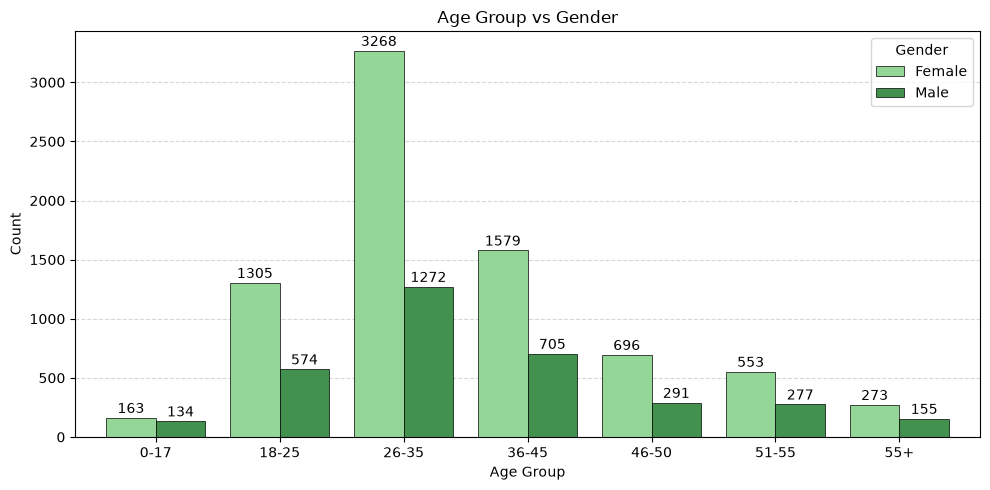

In [21]:
# Grouped bar chart: Age Group vs Gender

result = df.groupby(['Age Group', 'Gender'])['Gender'].count().unstack()

fig, ax = plt.subplots(figsize=(10, 5))

bar = result.plot(
    kind='bar',
    ax=ax,
    width=0.8,
    zorder=2,
    color=['#94D698', '#43914F'],
    edgecolor='black',
    linewidth=0.5
)

# Add labels on bars
for container in bar.containers:
    ax.bar_label(container, padding=1, fontsize=10)

ax.set_title('Age Group vs Gender')
ax.set_xlabel('Age Group')
ax.set_ylabel('Count')

ax.legend(title='Gender')
ax.tick_params(axis='x', labelrotation=0)
ax.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)
plt.tight_layout()
plt.show()


### Top 5 States by Sales


State
Uttar Pradesh     19380394.0
Maharashtra       14450091.0
Karnataka         13543778.0
Delhi             11645323.5
Madhya Pradesh     8126142.0
Name: Amount, dtype: float64


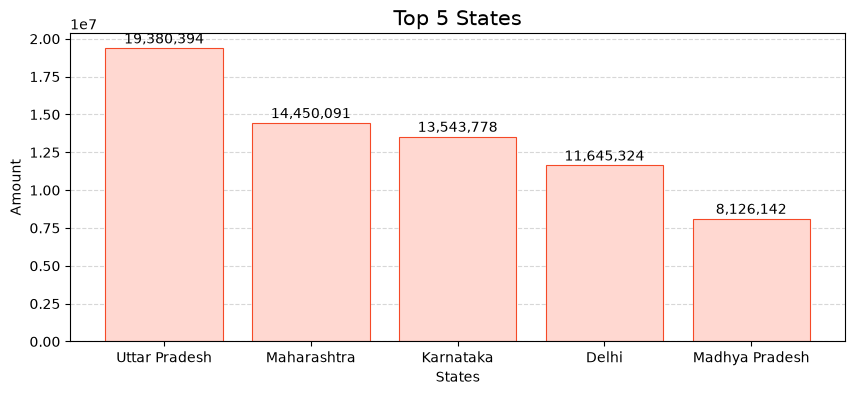

In [22]:
# Top 5 states by total sales amount
x = df.groupby('State')['Amount'].sum().sort_values(ascending=False).head(5)
print(x)
fig, ax = plt.subplots(figsize=(10,4))
bar = plt.bar(
        x.index,
        x.values,
        color='#FFD8D1', 
        edgecolor='#F54927', 
        linewidth=.8, 
        zorder=2,
    )
ax.bar_label(bar, padding=1, fontsize=10,fmt='{:,.0f}')
ax.set_title('Top 5 States', fontsize=15)
ax.set_xlabel('States')
ax.set_ylabel('Amount')
plt.grid(linestyle='--', axis='y', alpha=.5)
plt.show()

### Product Category Distribution


Product_Category
Beauty         2333
Clothing       2179
Electronics    2235
Health         2222
Sports         2276
Name: Product_Category, dtype: int64


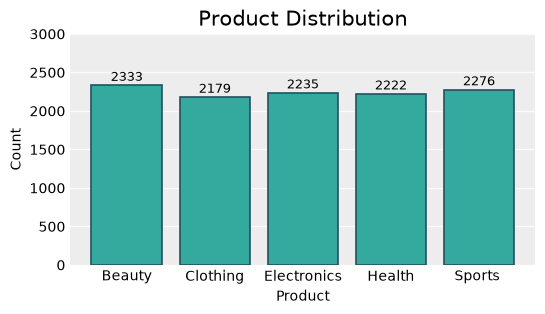

In [23]:
# Product category distribution (count)
pcc = df.groupby('Product_Category')['Product_Category'].count()
print(pcc)

fig, ax = plt.subplots(figsize=(6,3), dpi=100)
bar = ax.bar(pcc.index,
       pcc.values,
       zorder = 2,
       color=["#34A99D"],
       edgecolor=["#255063"],
       linewidth=1.2
       )
ax.bar_label(bar, padding=1, fontsize=9)
ax.set_title('Product Distribution', fontsize=15)
ax.set_xlabel('Product')
ax.set_ylabel('Count')
ax.set_ylim(0,3000)
ax.grid(linestyle='-',color='white',linewidth=1, alpha=.8, axis='y')
ax.set_facecolor('#EDEDED')
sns.despine(ax=ax, top=True, bottom=True, left=True, right=True)
ax.tick_params(axis='both', length=0)
plt.show()

### Profession Distribution


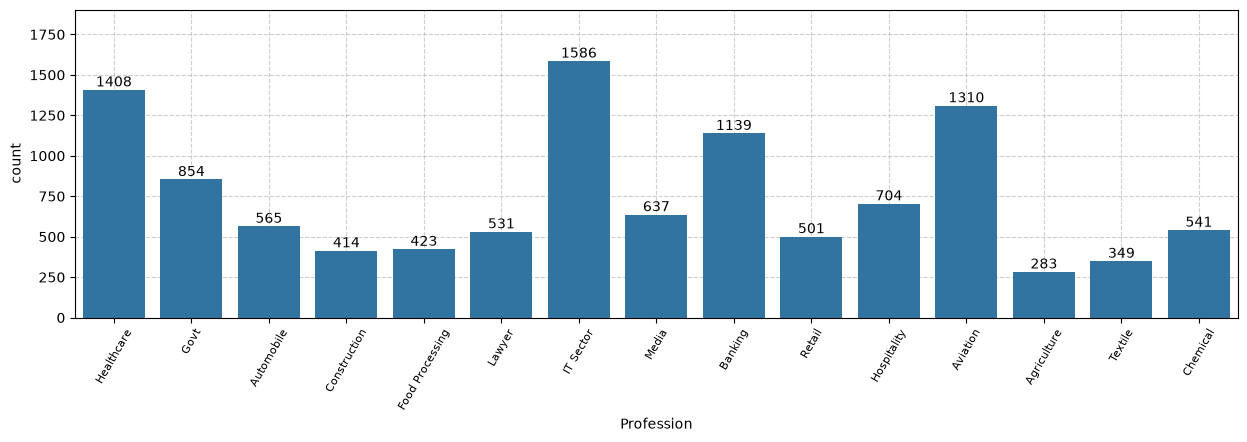

In [24]:
# Count of customers by Profession
plt.figure(figsize=(15,4))
ax = sns.countplot(data=df, x='Profession', zorder=2)
for bar in ax.containers:
    ax.bar_label(bar)
ax.margins(y=0.2)
plt.grid(linestyle='--', alpha=.6)
plt.xticks(rotation=60, ha='center', fontsize=8)
plt.show()

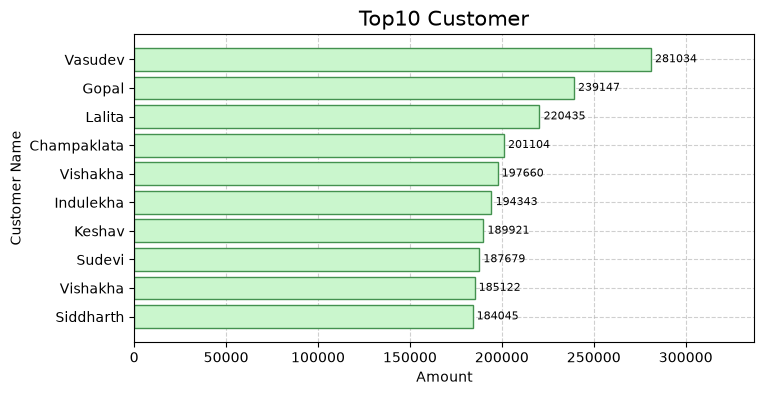

In [25]:
top10 = df.groupby(['User_ID','Cust_name'])['Amount'].sum().nlargest(10).reset_index()

fig, ax = plt.subplots(figsize=(8,4))
bar = ax.barh(
    range(len(top10)), top10['Amount'],
    color="#CAF6CD",
    edgecolor='#43914F',
    linewidth=1,
    zorder=2
)
ax.set_yticks(range(len(top10)))
ax.set_yticklabels(top10['Cust_name'])
ax.bar_label(bar , padding=3 , fontsize=8)
ax.invert_yaxis()

ax.margins(x=.2)
ax.set_title('Top10 Customer', fontsize=15)
ax.set_xlabel('Amount')
ax.set_ylabel('Customer Name')
ax.grid(linestyle='--', alpha=.6)
plt.show()